In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X = np.array([
    [4, 11],
    [8, 4],
    [13, 5],
    [7,14]]
)
X

array([[ 4, 11],
       [ 8,  4],
       [13,  5],
       [ 7, 14]])

In [3]:
X.shape

(4, 2)

In [4]:
X_mean = np.mean(X, axis=0)
X_mean

array([8. , 8.5])

In [5]:
X_centered = X - X_mean
X_centered

array([[-4. ,  2.5],
       [ 0. , -4.5],
       [ 5. , -3.5],
       [-1. ,  5.5]])

In [6]:
cov_matrix = np.cov(X_centered, rowvar=False)
cov_matrix

array([[ 14., -11.],
       [-11.,  23.]])

In [7]:
# eigh is for symmetric matrices (covariance) and returns REAL eigenvalues/eigenvectors.
# np.linalg.eig can return complex dtype (+0j), which breaks plt.arrow.
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
print(f"Sorted Indices: {idx}")
eigenvalues, eigenvectors
# NOTE: the sign of an eigenvector is arbitrary. Slide 17 shows scores with the opposite sign
# (-4.3052, 3.7361, 5.6928, -5.1238): u1 and -u1 are both correct.

Sorted Indices: [1 0]


(array([30.38486432,  6.61513568]),
 array([[-0.55738997, -0.83025082],
        [ 0.83025082, -0.55738997]]))

In [8]:
components = eigenvectors[:, 0:1]          # shape (2, 1)
components

array([[-0.55738997],
       [ 0.83025082]])

In [9]:
PC = X_centered.dot(components)            # shape (4, 1)
PC

array([[ 4.30518692],
       [-3.73612869],
       [-5.69282771],
       [ 5.12376947]])

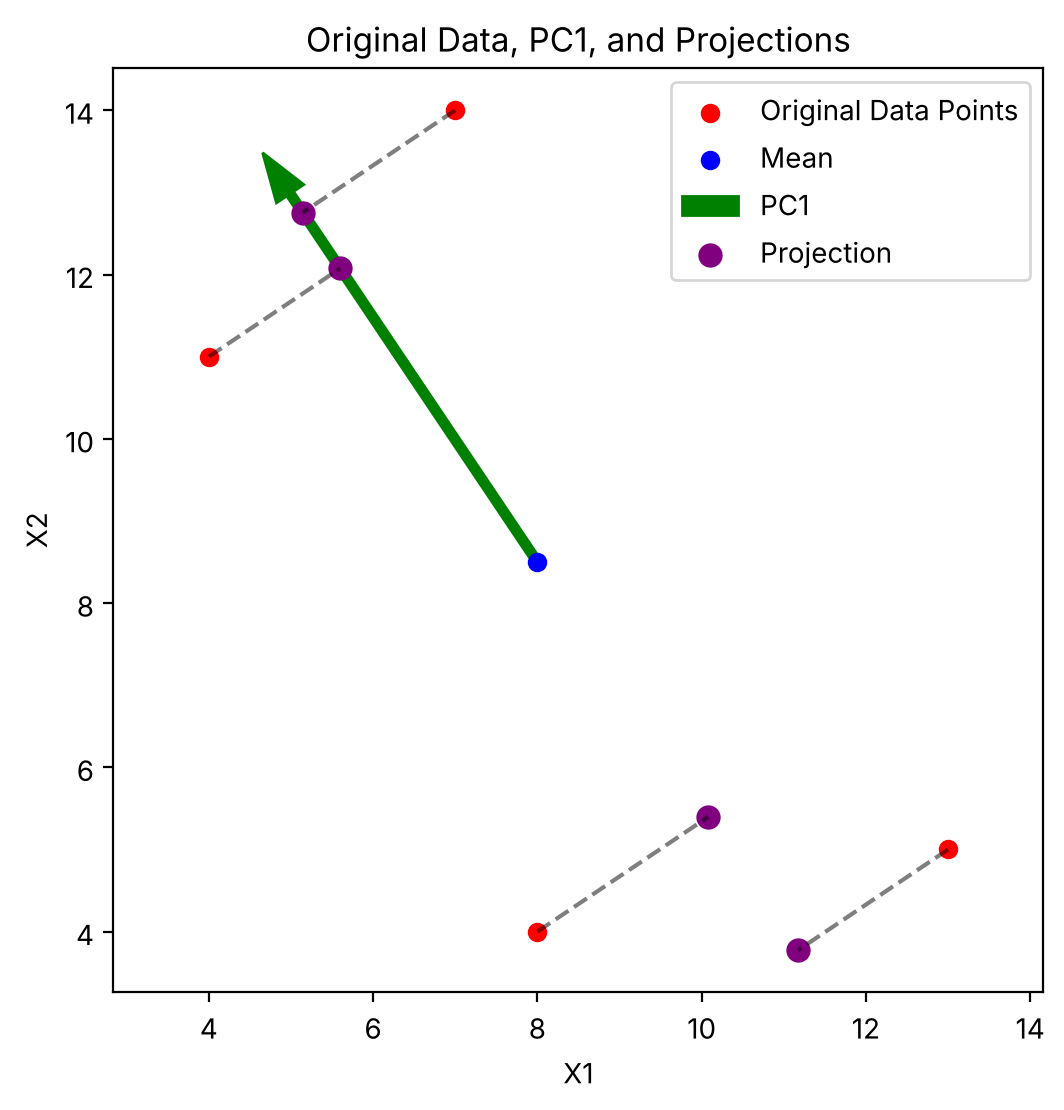

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], color='red', label='Original Data Points')
plt.scatter(X_mean[0], X_mean[1], color='blue', label='Mean', zorder=5)

scale = 6
vec = components[:, 0] * scale
plt.arrow(X_mean[0], X_mean[1], vec[0], vec[1],
          color='green', width=0.1, head_width=0.4,
          length_includes_head=True, label='PC1')

for i in range(X.shape[0]):
    proj = X_mean + PC[i, 0] * components[:, 0]
    plt.plot([X[i, 0], proj[0]], [X[i, 1], proj[1]], 'k--', alpha=0.5)
    plt.scatter(proj[0], proj[1], color='purple', s=60,
                label='Projection' if i == 0 else "")

plt.xlabel('X1'); plt.ylabel('X2')
plt.title('Original Data, PC1, and Projections')
plt.legend(); plt.axis('equal'); plt.show()

### **PCA with Class method**

In [11]:
import numpy as np

class PCAScratch:  # not called PCA, so it does not shadow sklearn.decomposition.PCA
    def __init__(self, n_components):
        """
        n_components: number of principal components to keep
        """
        self.n_components = n_components
        self.mean_ = None
        self.components_ = None
        self.explained_variance_ = None

    def fit(self, X):
        """
        Fit the PCA model to dataset X.
        X: shape (n_samples, n_features)
        """
        # 1️⃣ Step 1: Center the data (zero mean)
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # 2️⃣ Step 2: Compute covariance matrix (d x d)
        # Cov = X^T X / (m-1)  (np.cov uses the divisor m-1)
        cov_matrix = np.cov(X_centered, rowvar=False)

        # 3️⃣ Step 3: Compute eigenvalues & eigenvectors
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        # eigh is used because covariance matrix is symmetric

        # 4️⃣ Step 4: Sort eigenvalues (descending) and eigenvectors accordingly
        sorted_idx = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[sorted_idx]
        eigenvectors = eigenvectors[:, sorted_idx]

        # 5️⃣ Step 5: Select top-k eigenvectors
        self.components_ = eigenvectors[:, :self.n_components]
        self.explained_variance_ = eigenvalues[:self.n_components]
        self.explained_variance_ratio_ = eigenvalues[:self.n_components] / eigenvalues.sum()
        return self  # allows PCAScratch(2).fit(X).transform(X)

    def transform(self, X):
        """
        Project data onto the principal components
        """
        X_centered = X - self.mean_
        return np.dot(X_centered, self.components_)

    def fit_transform(self, X):
        """
        Fit to data, then transform it
        """
        self.fit(X)
        return self.transform(X)

    def inverse_transform(self, Z):
        """Map scores back to the original space (reconstruction)."""
        return Z @ self.components_.T + self.mean_


In [12]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=1000, n_features=800, n_informative=10, n_redundant=5, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (800, 800), X_test shape: (200, 800)


In [13]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

svm = SVC(kernel='linear', random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42)

svm.fit(X_train, y_train)
rf.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
y_pred_rf = rf.predict(X_test)
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("SVM Classification Report:\n", classification_report(y_test, y_pred_svm))
print("Random Forest Classification Report:\n", classification_report(y_test, y_pred_rf))


SVM Accuracy: 0.73
Random Forest Accuracy: 0.745
SVM Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.72      0.76       120
           1       0.64      0.75      0.69        80

    accuracy                           0.73       200
   macro avg       0.72      0.73      0.73       200
weighted avg       0.74      0.73      0.73       200

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.72      0.77       120
           1       0.65      0.79      0.71        80

    accuracy                           0.74       200
   macro avg       0.74      0.75      0.74       200
weighted avg       0.76      0.74      0.75       200



In [14]:
# Split first, then fit PCA on the TRAINING data only (avoids data leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pca = PCAScratch(n_components=50).fit(X_train)
X_train_red = pca.transform(X_train)
X_test_red = pca.transform(X_test)

print("Original shape:", X_train.shape)
print("Reduced shape:", X_train_red.shape)

Original shape: (800, 800)
Reduced shape: (800, 50)


In [15]:
# Keep the raw arrays; use new names for the reduced ones (re-running this cell is now safe)
print(f"X_train_red shape: {X_train_red.shape}, X_test_red shape: {X_test_red.shape}")

X_train_red shape: (800, 50), X_test_red shape: (200, 50)


In [16]:
# Same models, now on the 50 PCA scores
svm = SVC(kernel='linear', random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42)

svm.fit(X_train_red, y_train)
rf.fit(X_train_red, y_train)
y_pred_svm = svm.predict(X_test_red)
y_pred_rf = rf.predict(X_test_red)
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("SVM Classification Report:\n", classification_report(y_test, y_pred_svm))
print("Random Forest Classification Report:\n", classification_report(y_test, y_pred_rf))


SVM Accuracy: 0.805
Random Forest Accuracy: 0.795
SVM Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.79      0.83       120
           1       0.73      0.82      0.77        80

    accuracy                           0.81       200
   macro avg       0.80      0.81      0.80       200
weighted avg       0.81      0.81      0.81       200

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.78      0.82       120
           1       0.71      0.82      0.76        80

    accuracy                           0.80       200
   macro avg       0.79      0.80      0.79       200
weighted avg       0.81      0.80      0.80       200



### **Checks and extensions (added in the corrected notebook)**
The tests below correspond to Chapter 12 of the guide.

In [17]:
from sklearn.decomposition import PCA as SkPCA

# 1. Our class against scikit-learn on the small example (axes agree up to sign)
Xs = np.array([[4, 11], [8, 4], [13, 5], [7, 14]], dtype=float)
mine = PCAScratch(1).fit(Xs)
ref = SkPCA(n_components=1).fit(Xs)
print("eigenvalue  :", mine.explained_variance_, ref.explained_variance_)
print("|cos|       :", abs(mine.components_[:, 0] @ ref.components_[0]))
Z = mine.transform(Xs)
print("squared reconstruction error:", ((Xs - mine.inverse_transform(Z))**2).sum(),
      "= (m-1)*lambda_2 =", 3 * 6.6151)

eigenvalue  : [30.38486432] [30.38486432]
|cos|       : 0.9999999999999999
squared reconstruction error: 19.84540702798587 = (m-1)*lambda_2 = 19.8453


In [18]:
# 2. Ten seeds instead of one split; PCA inside a Pipeline so it is fitted on training data only
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def run(seed, scale=False):
    X, y = make_classification(n_samples=1000, n_features=800, n_informative=10,
                               n_redundant=5, random_state=seed)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    steps = ([StandardScaler()] if scale else []) + [SkPCA(n_components=50, random_state=seed),
                                                      SVC(kernel='linear', random_state=seed)]
    raw = SVC(kernel='linear', random_state=seed).fit(Xtr, ytr).score(Xte, yte)
    return raw, make_pipeline(*steps).fit(Xtr, ytr).score(Xte, yte)

for scale in (False, True):
    r = np.array([run(s, scale) for s in range(10)])
    print(f"standardise first = {scale}:  raw {r[:,0].mean():.3f}  PCA(50) {r[:,1].mean():.3f}"
          f"  PCA wins {(r[:,1] > r[:,0]).sum()}/10")

standardise first = False:  raw 0.728  PCA(50) 0.817  PCA wins 10/10


standardise first = True:  raw 0.728  PCA(50) 0.716  PCA wins 3/10


Standardising before PCA is a rule of thumb, not a law: in this synthetic problem the informative features have variance about 4 and the noise features variance 1, so standardising throws that signal away (see Chapter 12).